# Test 1 — do fixed-length token drafts cut through Hindi words / aksharas?
Runtime: **CPU is enough** (no GPU needed). Run all cells top to bottom.
Before running: add a Colab secret named `HF_TOKEN` (key icon, left sidebar) and accept the Llama-3.2 license + FLORES+ terms on Hugging Face with that account.

In [ ]:
# Hugging Face login (Colab secret -> env var -> prompt)
import os
tok = None
try:
    from google.colab import userdata
    tok = userdata.get("HF_TOKEN")
except Exception:
    tok = os.environ.get("HF_TOKEN")
if not tok:
    from getpass import getpass
    tok = getpass("Paste HF token (or press Enter to skip): ").strip() or None
if tok:
    os.environ["HF_TOKEN"] = tok
    from huggingface_hub import login
    login(token=tok)
    print("logged in")
else:
    print("no token: gated models (Llama) will be skipped")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


logged in


In [ ]:
import csv, json, os, re, sys, unicodedata
from collections import Counter
from itertools import accumulate

# --------------------------------------------------------------------------- #
# token -> bytes
# --------------------------------------------------------------------------- #


def _bytes_to_unicode():
    """GPT-2 byte<->unicode table (used by Llama-3 and Qwen byte-level BPE)."""
    bs = (list(range(ord("!"), ord("~") + 1))
          + list(range(ord("\u00a1"), ord("\u00ac") + 1))
          + list(range(ord("\u00ae"), ord("\u00ff") + 1)))
    cs = bs[:]
    n = 0
    for b in range(256):
        if b not in bs:
            bs.append(b)
            cs.append(256 + n)
            n += 1
    return dict(zip(bs, [chr(c) for c in cs]))


BYTE_DECODER = {v: k for k, v in _bytes_to_unicode().items()}
_HEX_RE = re.compile(r"^<0x([0-9A-Fa-f]{2})>$")


def token_to_bytes(tok: str) -> bytes:
    m = _HEX_RE.match(tok)
    if m:  # SentencePiece byte-fallback token
        return bytes([int(m.group(1), 16)])
    if all(ch in BYTE_DECODER for ch in tok):  # GPT-2 style byte-level BPE
        return bytes(BYTE_DECODER[ch] for ch in tok)
    return tok.replace("\u2581", " ").encode("utf-8")  # SentencePiece unicode piece


class HFTok:
    """Thin wrapper: text -> list of token byte-strings."""

    def __init__(self, name_or_tokenizer):
        if isinstance(name_or_tokenizer, str):
            from transformers import AutoTokenizer
            self.name = name_or_tokenizer
            self.tok = AutoTokenizer.from_pretrained(name_or_tokenizer)
        else:
            self.name = "custom"
            self.tok = name_or_tokenizer

    def to_bytes(self, text):
        ids = self.tok(text, add_special_tokens=False)["input_ids"]
        return [token_to_bytes(t) for t in self.tok.convert_ids_to_tokens(ids)]


# --------------------------------------------------------------------------- #
# akshara + word boundaries
# --------------------------------------------------------------------------- #

_C = "\u0915-\u0939\u0958-\u095F\u0978-\u097F"      # consonants
_VIRAMA = "\u094D"
_NUKTA = "\u093C"
_ZW = "\u200C\u200D"                                 # ZWNJ / ZWJ
_IVOW = "\u0904-\u0914\u0960\u0961\u0972-\u0977"     # independent vowels
_MATRA = "\u093A\u093B\u093E-\u094C\u094E\u094F\u0955-\u0957\u0962\u0963"
_MOD = "\u0900-\u0903\u0951-\u0954"                  # candrabindu, anusvara, visarga, stress marks

_AKSHARA_RE = re.compile(
    rf"[{_C}]{_NUKTA}?(?:{_VIRAMA}[{_ZW}]?[{_C}]{_NUKTA}?)*(?:{_VIRAMA}[{_ZW}]?|[{_MATRA}]*)[{_MOD}]*"
    rf"|[{_IVOW}]{_NUKTA}?[{_MATRA}]*[{_MOD}]*"
)


def akshara_units(text):
    """Return list of (start, end) char spans. Non-Devanagari chars are single units
    with any following combining marks / ZW joiners attached."""
    units, i, n = [], 0, len(text)
    while i < n:
        m = _AKSHARA_RE.match(text, i)
        if m and m.end() > i:
            j = m.end()
        else:
            j = i + 1
            while j < n and (unicodedata.category(text[j]).startswith("M") or text[j] in "\u200c\u200d"):
                j += 1
        units.append((i, j))
        i = j
    return units


def is_word_boundary(text, c):
    n = len(text)
    if c <= 0 or c >= n:
        return True
    a, b = text[c - 1], text[c]
    if a.isspace() or b.isspace():
        return True
    if unicodedata.category(a).startswith("P") or unicodedata.category(b).startswith("P"):
        return True
    return False


END, WORD, MIDWORD, MIDAKS, MIDUTF8 = "end", "word_boundary", "mid_word", "mid_akshara", "mid_utf8"
TAG = {END: "E", WORD: "W", MIDWORD: "w", MIDAKS: "a", MIDUTF8: "u"}


def classify(b, total, byte2char, text, aks):
    if b >= total:
        return END
    c = byte2char.get(b)
    if c is None:
        return MIDUTF8
    if c not in aks:
        return MIDAKS
    return WORD if is_word_boundary(text, c) else MIDWORD


def sentence_features(tb):
    """tb: list of token byte-strings. Returns None if bytes are not valid UTF-8."""
    full = b"".join(tb)
    try:
        text = full.decode("utf-8")
    except UnicodeDecodeError:
        return None
    byte2char, pos = {}, 0
    for ci, ch in enumerate(text):
        byte2char[pos] = ci
        pos += len(ch.encode("utf-8"))
    byte2char[pos] = len(text)
    units = akshara_units(text)
    aks = {0} | {e for _, e in units}
    ends = list(accumulate(len(b) for b in tb))
    starts = [0] + ends[:-1]
    total = len(full)
    return {
        "text": text,
        "units": units,
        "cut": [classify(e, total, byte2char, text, aks) for e in ends],
        "start": [classify(s, total, byte2char, text, aks) for s in starts],
    }


# --------------------------------------------------------------------------- #
# corpus analysis
# --------------------------------------------------------------------------- #


def analyze(token_bytes_per_sentence, ks):
    tot = Counter()
    per_k = {k: Counter() for k in ks}
    for tb in token_bytes_per_sentence:
        f = sentence_features(tb)
        if f is None:
            tot["skipped_invalid_utf8"] += 1
            continue
        n = len(tb)
        if n < 2:
            tot["skipped_short"] += 1
            continue
        text, cut, start = f["text"], f["cut"], f["start"]
        tot["sentences"] += 1
        tot["tokens"] += n
        tot["words"] += len(text.split())
        tot["chars"] += len(text)
        tot["aksharas"] += len(f["units"])
        tot["starts_mid_utf8"] += sum(1 for s in start if s == MIDUTF8)
        tot["starts_mid_akshara"] += sum(1 for s in start if s == MIDAKS)
        for j in range(n - 1):  # internal cuts only (a token follows)
            tot["cuts"] += 1
            tot["cut_" + cut[j]] += 1

        wb = [c in (WORD, END) for c in cut]
        pw = [0] + list(accumulate(1 if x else 0 for x in wb))
        last_wb, lw = [], -1
        for j in range(n):
            if wb[j]:
                lw = j
            last_wb.append(lw)
        next_wb, nw = [0] * n, n - 1
        for j in range(n - 1, -1, -1):
            if wb[j]:
                nw = j
            next_wb[j] = nw

        for k in ks:
            c = per_k[k]
            for s in range(0, n - k):
                e = s + k - 1
                cat = cut[e]
                c["windows"] += 1
                c[cat] += 1
                done = pw[e + 1] - pw[s]
                c["completed_words"] += done
                if done == 0:
                    c["zero_word"] += 1
                if cat not in (WORD, END):
                    c["mid_n"] += 1
                    c["fwd_sum"] += next_wb[e] - e
                    c["back_sum"] += e - last_wb[e]
    return tot, per_k


def pct(a, b):
    return 100.0 * a / b if b else float("nan")


def summarize(name, tot, per_k, ks):
    S = {
        "tokenizer": name,
        "sentences": tot["sentences"],
        "tokens": tot["tokens"],
        "tokens_per_word": tot["tokens"] / max(tot["words"], 1),
        "tokens_per_akshara": tot["tokens"] / max(tot["aksharas"], 1),
        "tokens_per_char": tot["tokens"] / max(tot["chars"], 1),
        "pct_tokens_start_mid_akshara": pct(tot["starts_mid_akshara"], tot["tokens"]),
        "pct_tokens_start_mid_utf8": pct(tot["starts_mid_utf8"], tot["tokens"]),
        "pct_cuts_word_boundary": pct(tot["cut_" + WORD] + tot["cut_" + END], tot["cuts"]),
        "pct_cuts_mid_word": pct(tot["cut_" + MIDWORD], tot["cuts"]),
        "pct_cuts_mid_akshara": pct(tot["cut_" + MIDAKS], tot["cuts"]),
        "pct_cuts_mid_utf8": pct(tot["cut_" + MIDUTF8], tot["cuts"]),
        "skipped_invalid_utf8": tot["skipped_invalid_utf8"],
        "per_k": [],
    }
    for k in ks:
        c = per_k[k]
        w = c["windows"]
        S["per_k"].append({
            "k": k,
            "windows": w,
            "pct_end_at_word_boundary": pct(c[WORD] + c[END], w),
            "pct_end_mid_word": pct(c[MIDWORD], w),
            "pct_end_mid_akshara": pct(c[MIDAKS], w),
            "pct_end_mid_utf8": pct(c[MIDUTF8], w),
            "pct_end_anywhere_inside_word": 100.0 - pct(c[WORD] + c[END], w) if w else float("nan"),
            "mean_words_completed": c["completed_words"] / w if w else float("nan"),
            "pct_drafts_completing_zero_words": pct(c["zero_word"], w),
            "mean_tokens_forward_to_boundary": c["fwd_sum"] / c["mid_n"] if c["mid_n"] else float("nan"),
            "mean_tokens_back_to_boundary": c["back_sum"] / c["mid_n"] if c["mid_n"] else float("nan"),
        })
    return S


def print_summary(S):
    print(f"\n=== {S['tokenizer']} ===")
    print(f"sentences={S['sentences']}  tokens={S['tokens']}  "
          f"tokens/word={S['tokens_per_word']:.2f}  tokens/akshara={S['tokens_per_akshara']:.2f}  "
          f"tokens/char={S['tokens_per_char']:.2f}")
    print(f"tokens that START mid-akshara: {S['pct_tokens_start_mid_akshara']:.1f}%   "
          f"mid-UTF-8: {S['pct_tokens_start_mid_utf8']:.1f}%")
    print(f"all token cuts -> word boundary {S['pct_cuts_word_boundary']:.1f}% | mid-word {S['pct_cuts_mid_word']:.1f}% | "
          f"mid-akshara {S['pct_cuts_mid_akshara']:.1f}% | mid-UTF-8 {S['pct_cuts_mid_utf8']:.1f}%")
    if S["skipped_invalid_utf8"]:
        print(f"WARNING: skipped {S['skipped_invalid_utf8']} sentences (token bytes not valid UTF-8)")
    hdr = ("k", "@word", "mid-word", "mid-aks", "mid-utf8", "inside-any", "words/draft", "0-word%", "fwd", "back")
    print("\n" + " ".join(f"{h:>11}" for h in hdr))
    for r in S["per_k"]:
        print(" ".join(f"{v:>11}" for v in (
            r["k"], f"{r['pct_end_at_word_boundary']:.1f}", f"{r['pct_end_mid_word']:.1f}",
            f"{r['pct_end_mid_akshara']:.1f}", f"{r['pct_end_mid_utf8']:.1f}",
            f"{r['pct_end_anywhere_inside_word']:.1f}", f"{r['mean_words_completed']:.2f}",
            f"{r['pct_drafts_completing_zero_words']:.1f}",
            f"{r['mean_tokens_forward_to_boundary']:.2f}", f"{r['mean_tokens_back_to_boundary']:.2f}")))
    print("(columns 2-6 are % of k-token drafts; fwd/back = avg tokens to move to the nearest word boundary "
          "when the draft ends inside a word)")


# --------------------------------------------------------------------------- #
# examples for slides
# --------------------------------------------------------------------------- #


def _show(b):
    try:
        return b.decode("utf-8").replace(" ", "\u2423")  # visible space
    except UnicodeDecodeError:
        return "<" + b.hex() + ">"


def render_example(tb, k):
    f = sentence_features(tb)
    if f is None:
        return "(invalid utf-8)"
    out = []
    for i, b in enumerate(tb):
        out.append(_show(b))
        if i < len(tb) - 1:
            out.append(f" \u2016[{TAG[f['cut'][i]]}] " if (i + 1) % k == 0 else " | ")
    return "".join(out)


EXAMPLE_LEGEND = ("Legend: | token boundary,  \u2016 end of a fixed-k draft,  tag = what the draft ends on: "
                  "W=word boundary, w=inside word, a=inside akshara, u=inside UTF-8 char, \u2423 = space\n")

# --------------------------------------------------------------------------- #
# data
# --------------------------------------------------------------------------- #

DEMO = [
    "भारत एक विशाल और विविधताओं से भरा देश है।",
    "विद्यार्थियों ने विद्यालय में सूर्योदय के समय प्रार्थना की।",
    "मौसम विभाग ने कल भारी बारिश की चेतावनी जारी की है।",
    "वैज्ञानिकों का मानना है कि जलवायु परिवर्तन का प्रभाव कृषि पर पड़ेगा।",
    "उसने अपने दोस्तों को खाने पर बुलाया और सबने मिलकर खाना खाया।",
]


def load_sentences(path, field):
    out = []
    with open(path, encoding="utf-8") as fh:
        if path.endswith(".jsonl"):
            for line in fh:
                if line.strip():
                    out.append(json.loads(line)[field])
        else:
            out = [ln.rstrip("\n") for ln in fh]
    return [unicodedata.normalize("NFC", s.strip()) for s in out if s.strip()]




In [ ]:
# quick sanity check of the akshara logic
for w, exp in {"क्षमा": ["क्ष","मा"], "विद्यालय": ["वि","द्या","ल","य"], "ज्ञान": ["ज्ञा","न"], "श्री": ["श्री"], "है।": ["है","।"]}.items():
    got = [w[a:b] for a, b in akshara_units(w)]
    assert got == exp, (w, got)
print("akshara segmentation OK")

akshara segmentation OK


In [ ]:
# ---- config ----
TOKENIZERS = ["meta-llama/Llama-3.2-1B-Instruct", "Qwen/Qwen3.5-0.8B"]
KS = [2, 3, 4, 5, 6, 7, 8]
K_FOCUS = 4
LIMIT = None          # e.g. 300 for a quick run

# ---- Hindi data: FLORES+ devtest (hin_Deva) from Hugging Face ----
def load_hindi():
    from datasets import load_dataset
    repo = "openlanguagedata/flores_plus"
    try:
        ds = load_dataset(repo, "hin_Deva", split="devtest")
    except Exception as e1:
        print("config load failed:", str(e1)[:150])
        ds = load_dataset(repo, split="devtest")
        cols = ds.column_names
        if "iso_639_3" in cols:
            ds = ds.filter(lambda r: r["iso_639_3"] == "hin" and r.get("iso_15924", "Deva") == "Deva")
    col = "text" if "text" in ds.column_names else ds.column_names[0]
    return [unicodedata.normalize("NFC", s.strip()) for s in ds[col] if s.strip()]

try:
    sents = load_hindi()
    print("FLORES+ loaded:", len(sents), "sentences")
except Exception as e:
    print("FLORES+ failed:", type(e).__name__, str(e)[:200])
    sents = None
    try:
        from google.colab import files
        print("Upload a Hindi .txt file (one sentence per line):")
        up = files.upload()
        name = next(iter(up))
        sents = load_sentences(name, "text")
    except Exception:
        pass
    if not sents:
        print("Falling back to 5 demo sentences (pipeline check only, NOT a result).")
        sents = [unicodedata.normalize("NFC", s) for s in DEMO]
if LIMIT:
    sents = sents[:LIMIT]
print(len(sents), "sentences; first:", sents[0])

README.md:   0%|          | 0.00/73.7k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/222 [00:00<?, ?it/s]

hin_Deva.jsonl:   0%|          | 0.00/619k [00:00<?, ?B/s]

hin_Deva.jsonl:   0%|          | 0.00/645k [00:00<?, ?B/s]

Generating dev split:   0%|          | 0/997 [00:00<?, ? examples/s]

Generating devtest split:   0%|          | 0/1012 [00:00<?, ? examples/s]

FLORES+ loaded: 1012 sentences
1012 sentences; first: उन्होंने कहा “कि अब हमारे पास 4 महीने उम्र वाले चूहे हैं जिन्हें मधुमेह नहीं है जो मधुमेह के रोगी थे। ”


In [ ]:
# ---- run the experiment ----
summaries, example_lines = [], []
for name in TOKENIZERS:
    try:
        tk = HFTok(name)
    except Exception as e:
        print(f"[skip] {name}: {type(e).__name__}: {str(e)[:160]}")
        continue
    tbs = [tk.to_bytes(s) for s in sents]
    tot, pk = analyze(tbs, KS)
    S = summarize(name, tot, pk, KS)
    summaries.append(S)
    print_summary(S)
    example_lines.append(f"### {name} (k={K_FOCUS})")
    example_lines += [render_example(tb, K_FOCUS) for tb in tbs[:6]]
    example_lines.append("")
assert summaries, "No tokenizer loaded. Check HF token / license acceptance."
os.makedirs("results_test1", exist_ok=True)
json.dump(summaries, open("results_test1/summary.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
open("results_test1/examples.txt", "w", encoding="utf-8").write(EXAMPLE_LEGEND + "\n" + "\n".join(example_lines))

config.json:   0%|          | 0.00/877 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]


=== meta-llama/Llama-3.2-1B-Instruct ===
sentences=1012  tokens=68511  tokens/word=2.67  tokens/akshara=0.80  tokens/char=0.52
tokens that START mid-akshara: 53.5%   mid-UTF-8: 0.1%
all token cuts -> word boundary 38.6% | mid-word 6.9% | mid-akshara 54.3% | mid-UTF-8 0.1%

          k       @word    mid-word     mid-aks    mid-utf8  inside-any words/draft     0-word%         fwd        back
          2        39.0         6.7        54.2         0.1        61.0        0.78        27.8        1.72        1.75
          3        39.3         6.6        54.1         0.1        60.7        1.17        11.9        1.71        1.75
          4        39.4         6.5        54.1         0.1        60.6        1.56         4.5        1.71        1.74
          5        39.4         6.5        54.1         0.1        60.6        1.96         1.5        1.71        1.73
          6        39.3         6.4        54.1         0.1        60.7        2.35         0.4        1.70        1.73
     

config.json:   0%|          | 0.00/2.91k [00:00<?, ?B/s]

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

chat_template.jinja:   0%|          | 0.00/7.75k [00:00<?, ?B/s]


=== Qwen/Qwen3.5-0.8B ===
sentences=1012  tokens=85415  tokens/word=3.33  tokens/akshara=0.99  tokens/char=0.65
tokens that START mid-akshara: 45.8%   mid-UTF-8: 0.0%
all token cuts -> word boundary 33.0% | mid-word 20.6% | mid-akshara 46.4% | mid-UTF-8 0.0%

          k       @word    mid-word     mid-aks    mid-utf8  inside-any words/draft     0-word%         fwd        back
          2        33.3        20.3        46.3         0.0        66.7        0.65        39.6        2.20        2.24
          3        33.5        20.1        46.3         0.0        66.5        0.99        22.5        2.19        2.24
          4        33.6        20.1        46.2         0.0        66.4        1.31        11.5        2.18        2.24
          5        33.7        20.1        46.2         0.0        66.3        1.64         5.5        2.18        2.23
          6        33.7        20.0        46.2         0.0        66.3        1.97         2.5        2.18        2.22
          7        

7526

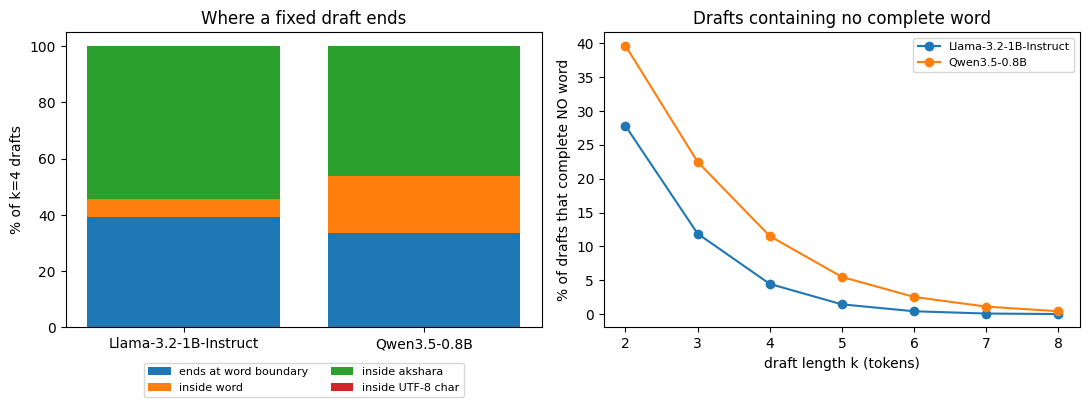

In [ ]:
# ---- plot ----
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
labels = [S["tokenizer"].split("/")[-1] for S in summaries]
parts = [("pct_end_at_word_boundary", "ends at word boundary"), ("pct_end_mid_word", "inside word"),
         ("pct_end_mid_akshara", "inside akshara"), ("pct_end_mid_utf8", "inside UTF-8 char")]
bottom = [0.0] * len(summaries)
for key, lab in parts:
    vals = [next(r for r in S["per_k"] if r["k"] == K_FOCUS)[key] for S in summaries]
    ax[0].bar(labels, vals, bottom=bottom, label=lab)
    bottom = [b + v for b, v in zip(bottom, vals)]
ax[0].set_ylabel(f"% of k={K_FOCUS} drafts"); ax[0].set_title("Where a fixed draft ends")
ax[0].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
for S, lab in zip(summaries, labels):
    ax[1].plot([r["k"] for r in S["per_k"]], [r["pct_drafts_completing_zero_words"] for r in S["per_k"]], marker="o", label=lab)
ax[1].set_xlabel("draft length k (tokens)"); ax[1].set_ylabel("% of drafts that complete NO word")
ax[1].set_title("Drafts containing no complete word"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("results_test1/test1_plot.png", dpi=160); plt.show()

In [ ]:
# ---- headline numbers for the slide + examples ----
for S in summaries:
    r = next(r for r in S["per_k"] if r["k"] == K_FOCUS)
    print(f"{S['tokenizer']}: {S['tokens_per_word']:.2f} tokens/word | "
          f"{S['pct_cuts_word_boundary']:.0f}% of token cuts are word boundaries | "
          f"k={K_FOCUS} drafts end inside a word {r['pct_end_anywhere_inside_word']:.0f}% of the time "
          f"(inside akshara {r['pct_end_mid_akshara']:.0f}%, inside UTF-8 char {r['pct_end_mid_utf8']:.0f}%) | "
          f"{r['pct_drafts_completing_zero_words']:.0f}% of drafts complete no word")
print()
print(EXAMPLE_LEGEND)
print("\n".join(example_lines)[:4000])

meta-llama/Llama-3.2-1B-Instruct: 2.67 tokens/word | 39% of token cuts are word boundaries | k=4 drafts end inside a word 61% of the time (inside akshara 54%, inside UTF-8 char 0%) | 4% of drafts complete no word
Qwen/Qwen3.5-0.8B: 3.33 tokens/word | 33% of token cuts are word boundaries | k=4 drafts end inside a word 66% of the time (inside akshara 46%, inside UTF-8 char 0%) | 12% of drafts complete no word

Legend: | token boundary,  ‖ end of a fixed-k draft,  tag = what the draft ends on: W=word boundary, w=inside word, a=inside akshara, u=inside UTF-8 char, ␣ = space

### meta-llama/Llama-3.2-1B-Instruct (k=4)
उन | ्ह | ों | न ‖[a] े | ␣कह | ा | ␣“ ‖[W] क | ि | ␣अब | ␣हम ‖[a] ार | े | ␣प | ास ‖[W] ␣ | 4 | ␣मह | ीन ‖[a] े | ␣उम | ्र | ␣व ‖[a] ाल | े | ␣च | ूह ‖[a] े | ␣ह | ैं | ␣ज ‖[a] िन | ्ह | ें | ␣मध ‖[a] ुम | ेह | ␣नह | ीं ‖[W] ␣ह | ै | ␣ज | ो ‖[W] ␣मध | ुम | ेह | ␣क ‖[a] े | ␣र | ोग | ी ‖[W] ␣थ | े। | ␣”
ड | ॉ | . | ␣ए ‖[w] ह | ुड | ␣उ | र ‖[W] , | ␣न | ोव | ा ‖[W] ␣स | ्क | ो